 # Task 1: Data Loading and Inspection

Import Required Libraries

In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns



Load Dataset

In [34]:
aml_df= pd.read_csv("../data/AML Transaction Data/SAML-D.csv")

aml_df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


Dataset Shape

In [35]:
aml_df.shape


(9504852, 12)

Column Names

In [36]:
aml_df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

Data Types

In [37]:
aml_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    object 
 1   Date                    object 
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        object 
 6   Received_currency       object 
 7   Sender_bank_location    object 
 8   Receiver_bank_location  object 
 9   Payment_type            object 
 10  Is_laundering           int64  
 11  Laundering_type         object 
dtypes: float64(1), int64(3), object(8)
memory usage: 870.2+ MB


Summary Statistics

In [38]:
aml_df.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


Missing Values

In [39]:
aml_df.isnull().sum()


Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

Task 2 : Data Cleaning

Duplicate Records

In [40]:
aml_df.duplicated().sum()

np.int64(0)

Outlier Analysis

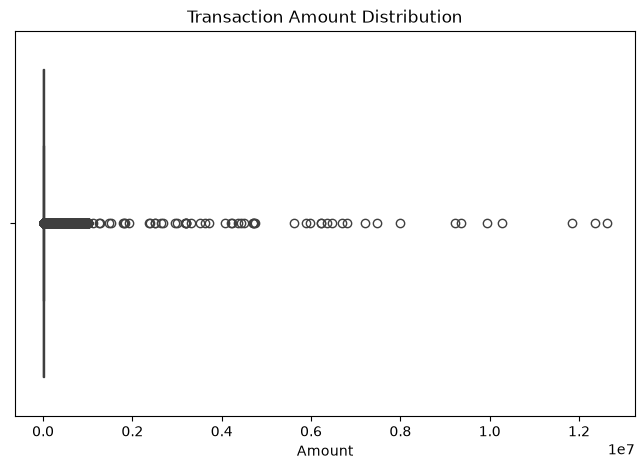

In [41]:
plt.figure(figsize=(8,5))
sns.boxplot(x=aml_df["Amount"])
plt.title("Transaction Amount Distribution")
plt.show()

 # Task 3: Exploratory Data Analysis (EDA)

Target Variable Distribution

In [42]:
print(aml_df.columns.tolist())

['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount', 'Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Is_laundering', 'Laundering_type']


In [43]:
aml_df["Is_laundering"].value_counts()

Is_laundering
0    9494979
1       9873
Name: count, dtype: int64

In [44]:
aml_df["Is_laundering"].value_counts(normalize=True) * 100

Is_laundering
0    99.896127
1     0.103873
Name: proportion, dtype: float64

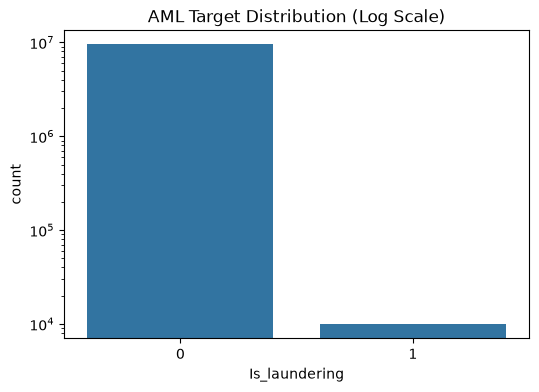

In [45]:
plt.figure(figsize=(6,4))

sns.countplot(x="Is_laundering", data=aml_df)

plt.yscale("log")

plt.title("AML Target Distribution (Log Scale)")
plt.show()

Transaction Amount Distribution

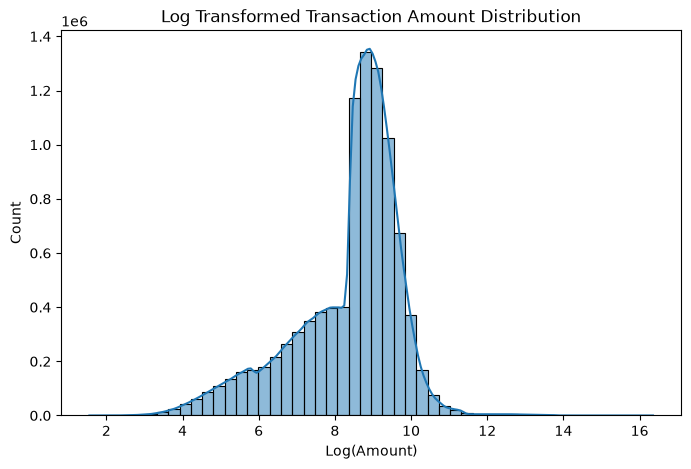

In [46]:
plt.figure(figsize=(8,5))

sns.histplot(
    np.log1p(aml_df["Amount"]),
    bins=50,
    kde=True
)

plt.title("Log Transformed Transaction Amount Distribution")
plt.xlabel("Log(Amount)")

plt.show()

Payment Type Analysis

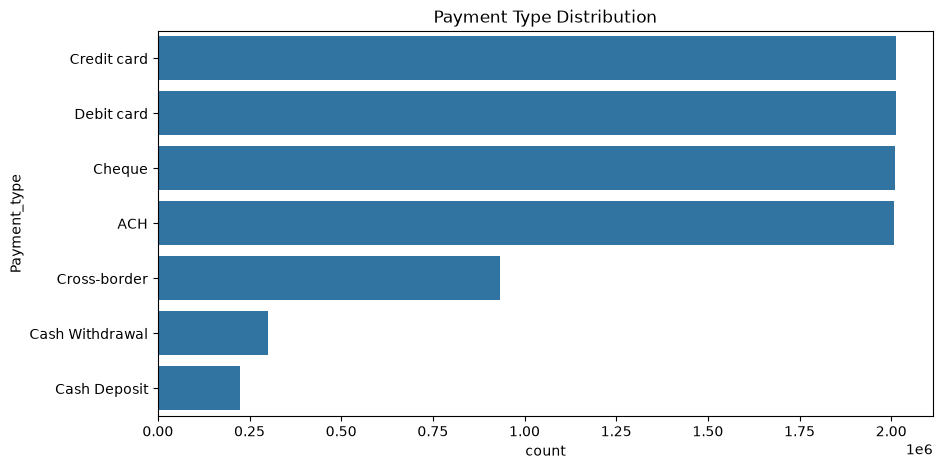

In [47]:
plt.figure(figsize=(10,5))

sns.countplot(
    y="Payment_type",
    data=aml_df,
    order=aml_df["Payment_type"].value_counts().index
)

plt.title("Payment Type Distribution")
plt.show()

Payment Currency Analysis

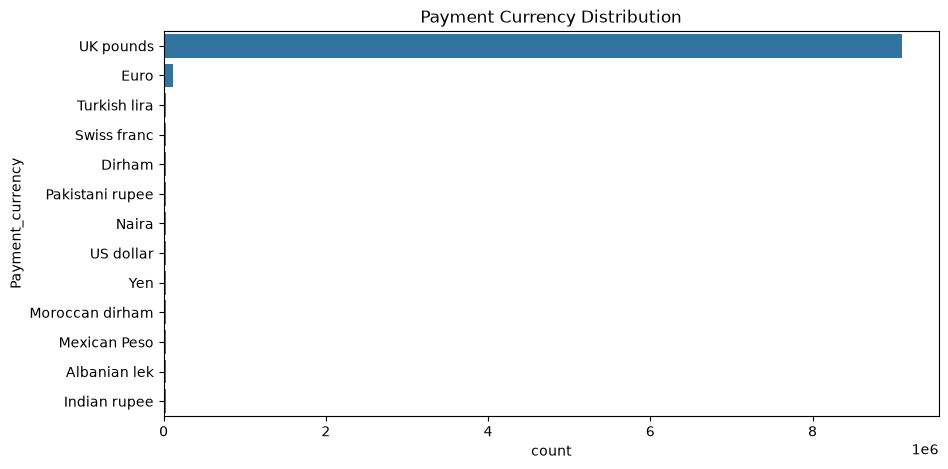

In [48]:
plt.figure(figsize=(10,5))

sns.countplot(
    y="Payment_currency",
    data=aml_df,
    order=aml_df["Payment_currency"].value_counts().index
)

plt.title("Payment Currency Distribution")
plt.show()

Received Currency Analysis

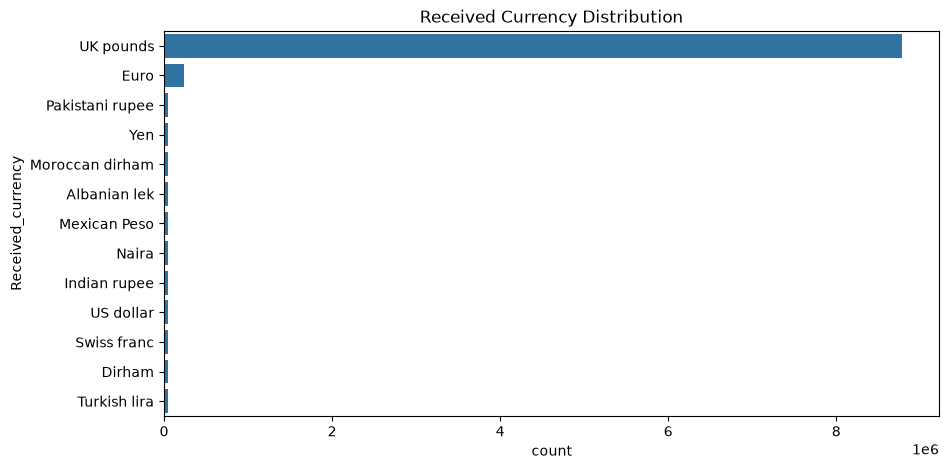

In [49]:
plt.figure(figsize=(10,5))

sns.countplot(
    y="Received_currency",
    data=aml_df,
    order=aml_df["Received_currency"].value_counts().index
)

plt.title("Received Currency Distribution")

plt.show()

Laundering Type Distribution

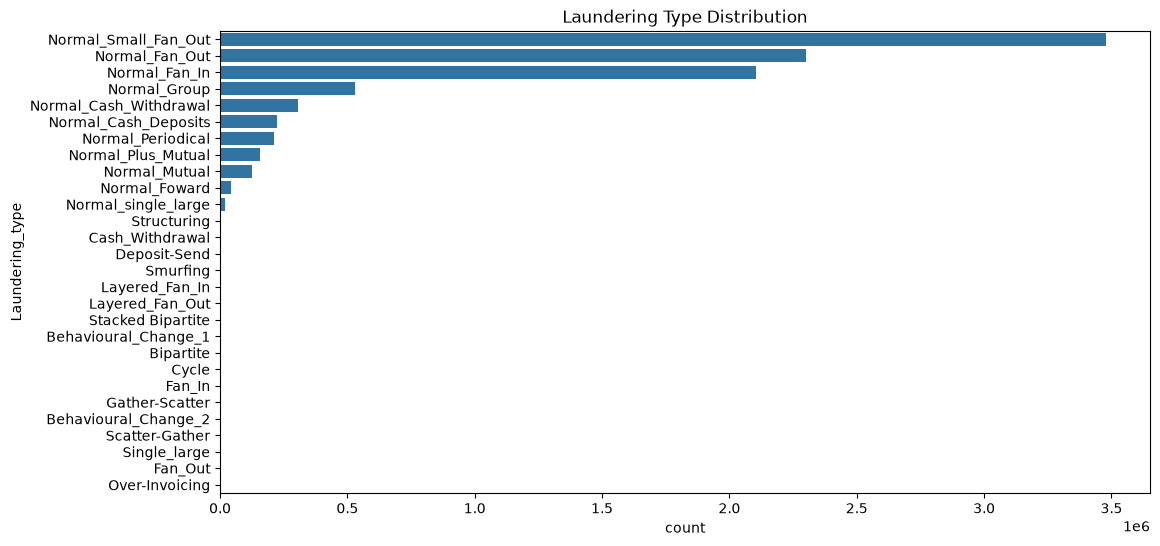

In [50]:
plt.figure(figsize=(12,6))

sns.countplot(
    y="Laundering_type",
    data=aml_df,
    order=aml_df["Laundering_type"].value_counts().index
)

plt.title("Laundering Type Distribution")

plt.show()

Correlation Analysis

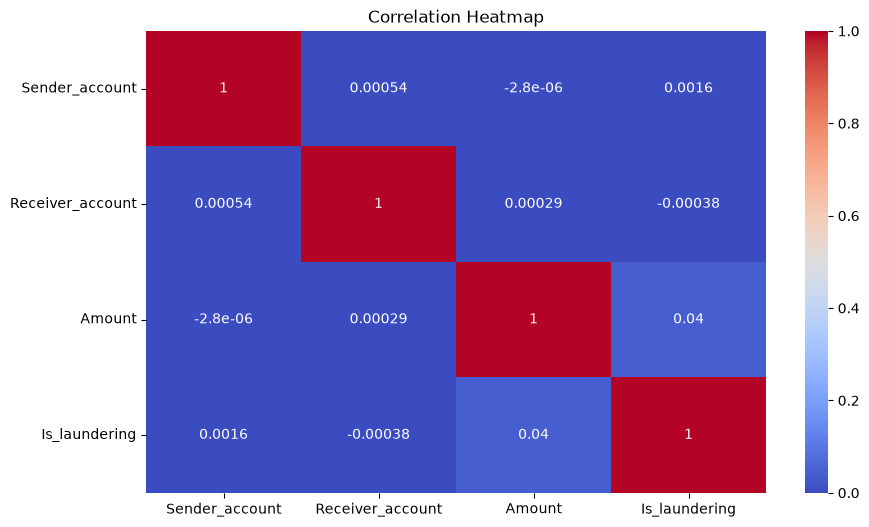

In [51]:
numeric_cols = aml_df.select_dtypes(include=np.number)

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

# Task 4: Feature Engineering

 Cross Border Flag

In [52]:
aml_df["Cross_Border"] = (
    aml_df["Sender_bank_location"] !=
    aml_df["Receiver_bank_location"]
).astype(int)

aml_df["Cross_Border"].value_counts()

Cross_Border
0    8570504
1     934348
Name: count, dtype: int64

Round Amount Indicator

In [53]:
aml_df["Round_Amount"] = (
    aml_df["Amount"] % 1000 == 0
).astype(int)

aml_df["Round_Amount"].value_counts()

Round_Amount
0    9504762
1         90
Name: count, dtype: int64

Check Time Column

In [54]:
aml_df["Time"].head()

0    10:35:19
1    10:35:20
2    10:35:20
3    10:35:21
4    10:35:21
Name: Time, dtype: object

In [55]:
aml_df["Time"].describe()

count      9504852
unique       86400
top       15:22:42
freq           201
Name: Time, dtype: object

Hour Feature

In [56]:
aml_df["Hour"] = pd.to_datetime(
    aml_df["Time"],
    format="%H:%M:%S"
).dt.hour

aml_df["Hour"].head()

0    10
1    10
2    10
3    10
4    10
Name: Hour, dtype: int32

Night Transaction Flag

In [57]:
aml_df["Night_Transaction"] = (
    (aml_df["Hour"] < 6) |
    (aml_df["Hour"] > 22)
).astype(int)

aml_df["Night_Transaction"].value_counts()

Night_Transaction
0    8255579
1    1249273
Name: count, dtype: int64

Hour-wise Transaction Analysis

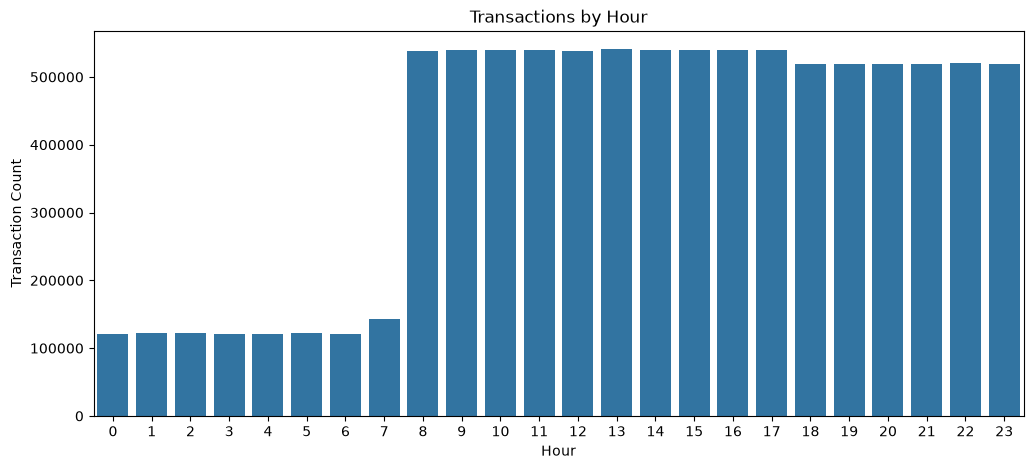

In [58]:
plt.figure(figsize=(12,5))

sns.countplot(
    x="Hour",
    data=aml_df
)

plt.title("Transactions by Hour")
plt.xlabel("Hour")
plt.ylabel("Transaction Count")

plt.show()


Round Amount Feature

In [59]:
aml_df["Round_Amount"] = (
    aml_df["Amount"] % 1000 == 0
).astype(int)

aml_df["Round_Amount"].value_counts()

Round_Amount
0    9504762
1         90
Name: count, dtype: int64

In [60]:
# Cross Currency Flag
aml_df["Cross_Currency"] = (
    aml_df["Payment_currency"] != aml_df["Received_currency"]
).astype(int)

aml_df["Cross_Currency"].value_counts()

Cross_Currency
0    8418990
1    1085862
Name: count, dtype: int64

In [61]:
# Sender Transaction Count
aml_df["Sender_Txn_Count"] = aml_df.groupby(
    "Sender_account"
)["Sender_account"].transform("count")

aml_df["Sender_Txn_Count"].head()

0     15
1    495
2    221
3      9
4      6
Name: Sender_Txn_Count, dtype: int64

In [62]:
# Receiver Transaction Count
aml_df["Receiver_Txn_Count"] = aml_df.groupby(
    "Receiver_account"
)["Receiver_account"].transform("count")

aml_df["Receiver_Txn_Count"].head()

0     29
1     12
2     21
3    128
4    119
Name: Receiver_Txn_Count, dtype: int64

In [63]:
# Sender Total Amount
aml_df["Sender_Total_Amount"] = aml_df.groupby(
    "Sender_account"
)["Amount"].transform("sum")

aml_df["Sender_Total_Amount"].head()

0      27868.00
1    2915213.56
2    2247056.76
3     107439.96
4       6413.43
Name: Sender_Total_Amount, dtype: float64

In [64]:
# Receiver Total Amount
aml_df["Receiver_Total_Amount"] = aml_df.groupby(
    "Receiver_account"
)["Amount"].transform("sum")

aml_df["Receiver_Total_Amount"].head()


0     223823.77
1      72252.38
2     214014.49
3    1579878.44
4    1173957.73
Name: Receiver_Total_Amount, dtype: float64